# 08 - Cross-validation design

Grouped nested CV with states as groups (primary) and random nested CV as a reference.
Inner loop: 4 folds, used only for hyperparameter selection.

In [1]:
import json, sys, pathlib
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

METRICS = ROOT / "evaluation" / "metrics"
PRED = ROOT / "evaluation" / "predictions"
PLOTS = ROOT / "evaluation" / "plots"
ERRORS = ROOT / "evaluation" / "error_analysis"

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

def show(path):
    try:
        from IPython.display import Image, display
        display(Image(filename=str(path)))
    except Exception:
        print("plot written to", path)


## Fold geometry, grouped by state

In [2]:
folds = pd.read_csv(METRICS / "phase3_fold_results.csv")
grouped = folds[folds["scheme"] == "grouped"]
geometry = (grouped[grouped["model"] == "ridge"]
            .groupby(["configuration", "fold"])
            .agg(n_train=("n_train", "first"), n_test=("n_test", "first"),
                 states_train=("n_states_train", "first"), states_test=("n_states_test", "first")))
geometry

n_train  n_test  states_train  states_test
configuration    fold                                            
A_primary_640    1         512     128            29            6
                 2         512     128            28            7
                 3         512     128            28            7
                 4         512     128            27            8
                 5         512     128            28            7
A_restricted_628 1         502     126            29            6
                 2         502     126            28            7
                 3         503     125            28            7
                 4         502     126            27            8
                 5         503     125            28            7
B_augmented_628  1         502     126            29            6
                 2         502     126            28            7
                 3         503     125            28            7
                 4         502     126            27            8
                 5         503     125            28            7

## State separation check

For every fold, training states plus held-out states must equal all 35 states, with no overlap.

In [3]:
check = geometry.copy()
check["sum_states"] = check["states_train"] + check["states_test"]
print("distinct (train+test) state counts:", sorted(check["sum_states"].unique()))
print("total states in the dataset:", pd.read_csv(ROOT / "datasets" / "processed" / "district_analysis.csv")["state"].nunique())
assert (check["sum_states"] == 35).all()
assert (check["states_test"] > 0).all()
print("no state is split across train and test")

distinct (train+test) state counts: [np.int64(35)]
total states in the dataset: 35
no state is split across train and test


## Grouped versus random, same models and budgets

In [4]:
pivot = folds.groupby(["configuration", "model", "scheme"])["mae"].mean().unstack("scheme")
pivot["grouped_minus_random"] = pivot["grouped"] - pivot["random"]
pivot.sort_values("grouped").round(3)

scheme                                   grouped  random  grouped_minus_random
configuration    model                                                        
B_augmented_628  svr_rbf                   1.725   1.140                 0.585
                 elastic_net               1.748   1.447                 0.301
                 ridge                     1.749   1.436                 0.313
                 extra_trees               1.810   1.233                 0.577
                 hist_gradient_boosting    1.841   1.271                 0.570
                 knn                       1.863   1.263                 0.600
                 gradient_boosting         1.868   1.261                 0.606
                 random_forest             1.871   1.346                 0.525
A_primary_640    svr_rbf                   2.029   1.326                 0.704
A_restricted_628 extra_trees               2.089   1.370                 0.719
A_primary_640    extra_trees               2.092   1.359                 0.733
A_restricted_628 random_forest             2.099   1.492                 0.607
A_primary_640    random_forest             2.113   1.511                 0.602
A_restricted_628 gradient_boosting         2.143   1.442                 0.701
A_primary_640    hist_gradient_boosting    2.144   1.415                 0.729
A_restricted_628 knn                       2.146   1.348                 0.798
                 hist_gradient_boosting    2.151   1.472                 0.679
A_primary_640    knn                       2.164   1.335                 0.829
A_restricted_628 svr_rbf                   2.171   1.339                 0.832
                 ridge                     2.185   1.686                 0.499
A_primary_640    ridge                     2.188   1.673                 0.515
A_restricted_628 elastic_net               2.196   1.683                 0.513
                 decision_tree             2.253   1.872                 0.381
A_primary_640    elastic_net               2.254   1.665                 0.590
                 gradient_boosting         2.259   1.447                 0.811
                 dummy_mean                2.440   2.412                 0.028
B_augmented_628  dummy_mean                2.450   2.427                 0.023
A_restricted_628 dummy_mean                2.450   2.427                 0.023
A_primary_640    decision_tree             2.496   1.909                 0.587
B_augmented_628  decision_tree             2.506   1.785                 0.720

## Inner-loop selection is itself noisy

`best_inner_mae` is the best inner-CV score per outer fold. Its spread shows how much the tuning signal moves when the held-out states change.

In [5]:
folds[folds["model"] == "svr_rbf"].groupby(["configuration", "scheme"])["best_inner_mae"].describe().round(3)

count   mean    std    min    25%    50%    75%    max
configuration    scheme                                                         
A_primary_640    grouped    5.0  2.075  0.145  1.879  1.975  2.114  2.177  2.230
                 random     5.0  1.345  0.049  1.271  1.327  1.357  1.372  1.399
A_restricted_628 grouped    5.0  2.077  0.107  1.958  1.979  2.106  2.126  2.214
                 random     5.0  1.340  0.022  1.306  1.334  1.345  1.350  1.364
B_augmented_628  grouped    5.0  1.788  0.083  1.719  1.725  1.747  1.838  1.911
                 random     5.0  1.148  0.030  1.112  1.119  1.162  1.163  1.181

## Fold-level MAE, primary configuration

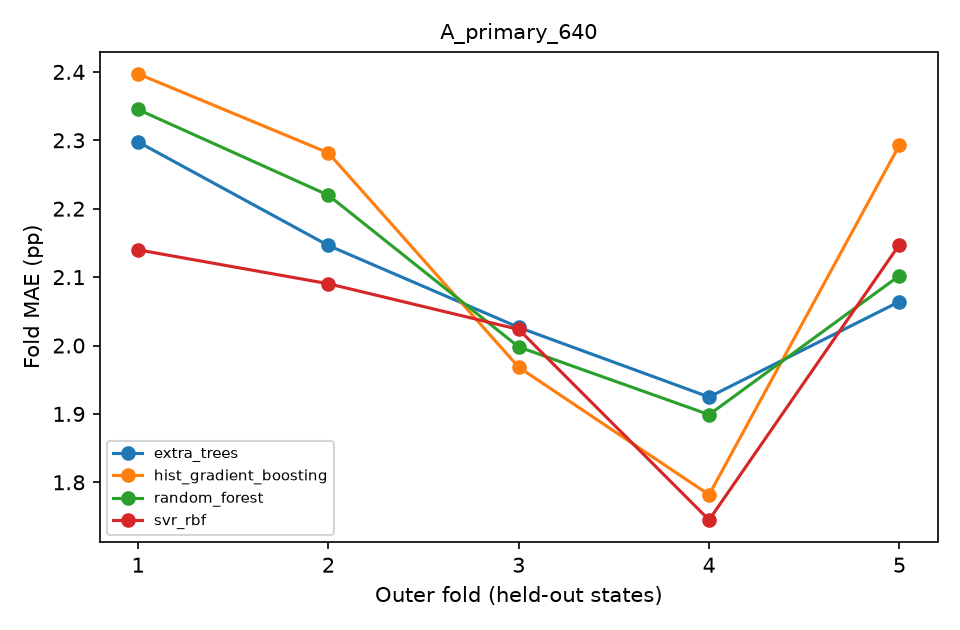

In [6]:
from src.evaluation import error_analysis as ea

path = PLOTS / "phase3_mae_by_fold_a640.png"
top_models = (pd.read_csv(METRICS / "phase3_model_comparison.csv")
              .query("configuration == 'A_primary_640'")
              .sort_values("rank")["model"].head(4).tolist())
ea.plot_mae_by_fold(grouped, "A_primary_640", top_models, path)
show(path)

## Why grouped CV is the primary estimate

Holding out whole states is the closest available proxy for predicting a district in a region the model has never seen. Random CV reuses the same states in training and testing, so it reports a materially optimistic error.